<a href="https://colab.research.google.com/github/supernova-sys/Quantum-not-so-computing/blob/main/vqc_moons_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 3: Variational quantum classifier on make_moons
Run the cells from top to bottom (Runtime > Run all). The first cell installs the packages.
If it asks you to restart the session, restart and then run all again.

In [ ]:
!pip install -q qiskit qiskit-machine-learning scikit-learn matplotlib pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.0 MB/s eta 0:00:00


In [ ]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA

SEED = 42
np.random.seed(SEED)

## 1. Data

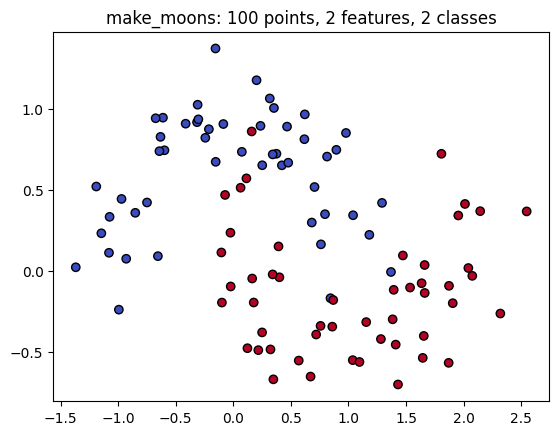

In [ ]:
X, y = make_moons(n_samples=100, noise=0.2, random_state=SEED)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
plt.title("make_moons: 100 points, 2 features, 2 classes")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

# squeeze x and y into 0..pi so they can be used as rotation angles
scaler = MinMaxScaler(feature_range=(0, np.pi)).fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

## 2. Classical baselines with a similar number of parameters

In [ ]:
def count_params(model):
    """Number of trainable numbers (weights + biases) in a fitted model."""
    est = model[-1] if hasattr(model, "steps") else model
    if hasattr(est, "coefs_"):
        return sum(w.size for w in est.coefs_) + sum(b.size for b in est.intercepts_)
    if hasattr(est, "coef_"):
        return est.coef_.size + est.intercept_.size
    if hasattr(est, "n_support_"):
        return int(est.n_support_.sum())
    return None

In [ ]:
def make_models(seed):
    return {
        "Logistic regression (linear)":
            LogisticRegression(),
        "Logistic regression + x^2 terms":
            make_pipeline(PolynomialFeatures(2, include_bias=False),
                          LogisticRegression(max_iter=1000)),
        "Small neural net (2 hidden)":
            MLPClassifier(hidden_layer_sizes=(2,), activation="tanh",
                          solver="lbfgs", max_iter=2000, random_state=seed),
        "SVM (RBF) - reference only":
            SVC(kernel="rbf"),
    }

results = {}
for name, model in make_models(SEED).items():
    t0 = time.time()
    model.fit(X_train_s, y_train)
    results[name] = dict(
        params=count_params(model),
        train_acc=accuracy_score(y_train, model.predict(X_train_s)),
        test_acc=accuracy_score(y_test,  model.predict(X_test_s)),
        time=time.time() - t0)

for k, v in results.items():
    print(f"{k:34s} params={v['params']:3d}  train={v['train_acc']:.2f}  test={v['test_acc']:.2f}")

Logistic regression (linear)       params=  3  train=0.87  test=0.83
Logistic regression + x^2 terms    params=  6  train=0.87  test=0.83
Small neural net (2 hidden)        params=  9  train=0.89  test=0.73
SVM (RBF) - reference only         params= 29  train=0.91  test=0.93


## 3. Qiskit's ready-made VQC (kept for comparison)

In [ ]:
num_features = X_train_s.shape[1]   # 2
feature_map = ZZFeatureMap(feature_dimension=num_features, reps=2)
ansatz      = RealAmplitudes(num_qubits=num_features, reps=3)
print("Trainable parameters:", ansatz.num_parameters)

loss_history = []
def callback(weights, loss):
    loss_history.append(loss)

vqc = VQC(feature_map=feature_map, ansatz=ansatz,
          optimizer=COBYLA(maxiter=100), callback=callback)

t0 = time.time()
vqc.fit(X_train_s, y_train)
vqc_time = time.time() - t0

results["VQC ready-made (ZZ + RealAmplitudes)"] = dict(
    params=ansatz.num_parameters,
    train_acc=vqc.score(X_train_s, y_train),
    test_acc=vqc.score(X_test_s, y_test),
    time=vqc_time)
print(f"Ready-made VQC trained in {vqc_time:.1f}s")

Trainable parameters: 8
Ready-made VQC trained in 34.8s


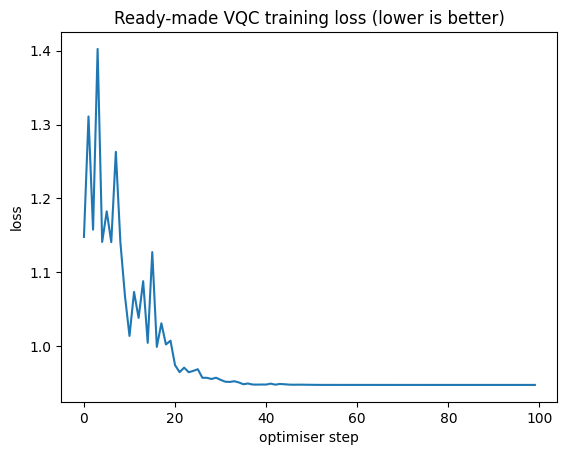

Model                                     params   train    test
Logistic regression (linear)                   3    0.87    0.83
Logistic regression + x^2 terms                6    0.87    0.83
Small neural net (2 hidden)                    9    0.89    0.73
SVM (RBF) - reference only                    29    0.91    0.93
VQC ready-made (ZZ + RealAmplitudes)           8    0.56    0.60


In [ ]:
plt.plot(loss_history)
plt.xlabel("optimiser step"); plt.ylabel("loss")
plt.title("Ready-made VQC training loss (lower is better)")
plt.show()

print(f"{'Model':40s}{'params':>8s}{'train':>8s}{'test':>8s}")
for k, v in results.items():
    print(f"{k:40s}{v['params']:8d}{v['train_acc']:8.2f}{v['test_acc']:8.2f}")

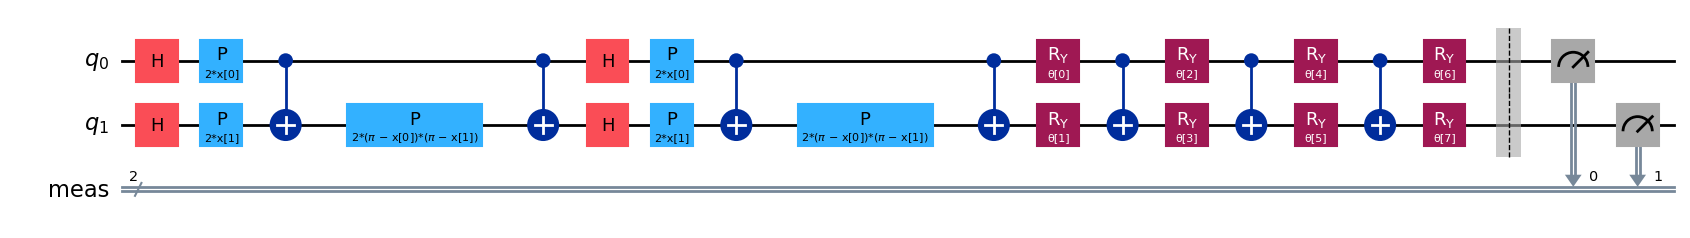

In [ ]:
feature_map.decompose().draw("mpl")
ansatz.decompose().draw("mpl")

full = feature_map.compose(ansatz)
full.measure_all()
full.decompose().draw("mpl")

## 4. Classical models over 10 different splits (mean and spread)

In [ ]:
accs = {}
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
    sc = MinMaxScaler(feature_range=(0, np.pi)).fit(Xa)
    Xa_s, Xb_s = sc.transform(Xa), sc.transform(Xb)
    for name, model in make_models(s).items():
        model.fit(Xa_s, ya)
        accs.setdefault(name, []).append(accuracy_score(yb, model.predict(Xb_s)))

print(f"{'Model':34s}{'mean test acc':>14s}{'std':>8s}")
for name, a in accs.items():
    print(f"{name:34s}{np.mean(a):14.3f}{np.std(a):8.3f}")

Model                              mean test acc     std
Logistic regression (linear)               0.850   0.056
Logistic regression + x^2 terms            0.840   0.061
Small neural net (2 hidden)                0.850   0.052
SVM (RBF) - reference only                 0.913   0.034


## 5. Our own VQC, built from scratch (feature map, ansatz, readout, loss)

In [ ]:
def my_feature_map(x):
    """Data in: x turns dial 0, y turns dial 1."""
    qc = QuantumCircuit(2)
    qc.ry(x[0], 0)
    qc.ry(x[1], 1)
    return qc

def make_ansatz(reps=3):
    """Learnable part: rotations with adjustable angles, linked by CNOTs."""
    theta = ParameterVector("theta", 2 * (reps + 1))
    qc = QuantumCircuit(2)
    k = 0
    for layer in range(reps + 1):
        qc.ry(theta[k], 0)
        qc.ry(theta[k + 1], 1)
        k += 2
        if layer < reps:
            qc.cx(0, 1)
    return qc, theta

my_ansatz, theta = make_ansatz(reps=3)
print("Learnable dials:", len(theta))

Learnable dials: 8


In [ ]:
def full_circuit(x):
    return my_feature_map(x).compose(my_ansatz)

def predict_proba(circuits, theta_values):
    """Chance that qubit 0 shows 1, for every data point."""
    fill = dict(zip(theta, theta_values))
    return np.array([
        Statevector(c.assign_parameters(fill)).probabilities([0])[1]
        for c in circuits])

def predict_labels(X, theta_values):
    """Readout: guess 1 if the chance of seeing 1 on qubit 0 is above 50%."""
    circuits = [full_circuit(x) for x in X]
    return (predict_proba(circuits, theta_values) > 0.5).astype(int)

def accuracy(pred, true):
    return np.mean(pred == true)

def make_loss(X, y):
    circuits = [full_circuit(x) for x in X]
    history = []
    def loss(theta_values):
        p1 = np.clip(predict_proba(circuits, theta_values), 1e-9, 1 - 1e-9)
        value = -np.mean(y * np.log(p1) + (1 - y) * np.log(1 - p1))
        history.append(value)
        return value
    return loss, history

def train(X, y, seed, maxiter=200):
    rng = np.random.default_rng(seed)
    start = rng.uniform(0, 2 * np.pi, len(theta))
    loss, history = make_loss(X, y)
    result = minimize(loss, start, method="COBYLA", options={"maxiter": maxiter})
    return result.x, history

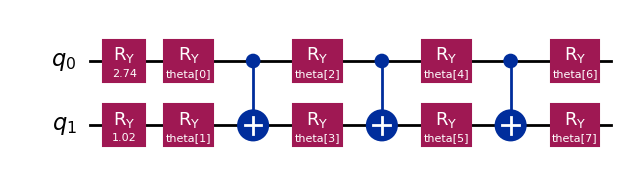

In [ ]:
# Look at the circuit for the first training point
full_circuit(X_train_s[0]).draw("mpl")

In [ ]:
# Check: after the feature map alone, P(qubit 0 = 1) should equal sin^2(x/2)
for x in [0.0, 1.0, 2.0, np.pi]:
    p1 = Statevector(my_feature_map([x, 0.0])).probabilities([0])[1]
    print(f"x={x:.2f}   circuit says {p1:.4f}   formula says {np.sin(x/2)**2:.4f}")

x=0.00   circuit says 0.0000   formula says 0.0000
x=1.00   circuit says 0.2298   formula says 0.2298
x=2.00   circuit says 0.7081   formula says 0.7081
x=3.14   circuit says 1.0000   formula says 1.0000


In [ ]:
t0 = time.time()
best_theta, history = train(X_train_s, y_train, seed=SEED)
my_time = time.time() - t0
print(f"Trained in {my_time:.1f}s")

Trained in 14.5s


Model                                     params   train    test
Logistic regression (linear)                   3    0.87    0.83
Logistic regression + x^2 terms                6    0.87    0.83
Small neural net (2 hidden)                    9    0.89    0.73
SVM (RBF) - reference only                    29    0.91    0.93
VQC ready-made (ZZ + RealAmplitudes)           8    0.56    0.60
VQC from scratch (RY)                          8    0.89    0.83


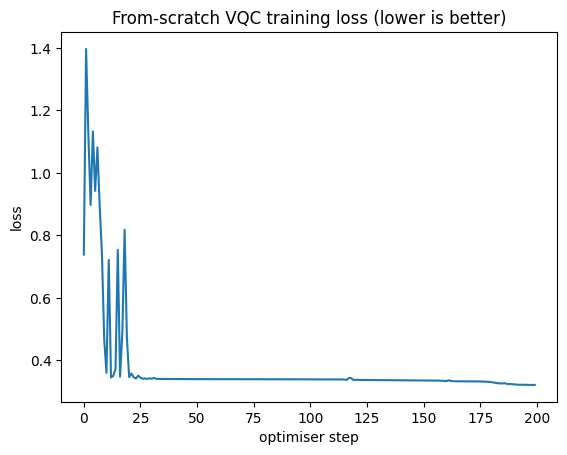

In [ ]:
train_acc = accuracy(predict_labels(X_train_s, best_theta), y_train)
test_acc  = accuracy(predict_labels(X_test_s,  best_theta), y_test)
results["VQC from scratch (RY)"] = dict(params=len(theta), train_acc=train_acc,
                                        test_acc=test_acc, time=my_time)

print(f"{'Model':40s}{'params':>8s}{'train':>8s}{'test':>8s}")
for k, v in results.items():
    print(f"{k:40s}{v['params']:8d}{v['train_acc']:8.2f}{v['test_acc']:8.2f}")

plt.plot(history)
plt.xlabel("optimiser step"); plt.ylabel("loss")
plt.title("From-scratch VQC training loss (lower is better)")
plt.show()

## 6. From-scratch VQC over 10 splits (slow: about 5 to 10 minutes)

In [ ]:
vqc_accs = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
    sc = MinMaxScaler(feature_range=(0, np.pi)).fit(Xa)
    Xa_s, Xb_s = sc.transform(Xa), sc.transform(Xb)
    th, _ = train(Xa_s, ya, seed=s)
    vqc_accs.append(accuracy(predict_labels(Xb_s, th), yb))
    print("split", s, "test acc", round(vqc_accs[-1], 3))

accs["VQC from scratch (RY)"] = vqc_accs
print()
print(f"{'Model':34s}{'mean test acc':>14s}{'std':>8s}")
for name, a in accs.items():
    print(f"{name:34s}{np.mean(a):14.3f}{np.std(a):8.3f}")

split 0 test acc 0.8
split 1 test acc 0.8
split 2 test acc 0.8
split 3 test acc 0.9
split 4 test acc 0.733
split 5 test acc 0.9
split 6 test acc 0.8
split 7 test acc 0.9
split 8 test acc 0.833
split 9 test acc 0.933

Model                              mean test acc     std
Logistic regression (linear)               0.850   0.056
Logistic regression + x^2 terms            0.840   0.061
Small neural net (2 hidden)                0.850   0.052
SVM (RBF) - reference only                 0.913   0.034
VQC from scratch (RY)                      0.840   0.061


## 7. Package versions (for the submission)

In [ ]:
import qiskit, qiskit_machine_learning, sklearn, scipy
print("qiskit", qiskit.__version__)
print("qiskit-machine-learning", qiskit_machine_learning.__version__)
print("scikit-learn", sklearn.__version__)
print("numpy", np.__version__)
print("scipy", scipy.__version__)
import matplotlib; print("matplotlib", matplotlib.__version__)

qiskit 2.6.0
qiskit-machine-learning 0.9.1
scikit-learn 1.6.1
numpy 2.1.3
scipy 1.16.3
matplotlib 3.10.0


In [ ]:
zz_accs = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
    sc = MinMaxScaler(feature_range=(0, np.pi)).fit(Xa)
    Xa_s, Xb_s = sc.transform(Xa), sc.transform(Xb)
    m = VQC(feature_map=ZZFeatureMap(feature_dimension=2, reps=2),
    ansatz=RealAmplitudes(num_qubits=2, reps=3),
    optimizer=COBYLA(maxiter=100),
    initial_point=np.random.default_rng(s).uniform(0, 2*np.pi, 8))
    m.fit(Xa_s, ya)
    zz_accs.append(m.score(Xb_s, yb))
    print("split", s, round(zz_accs[-1], 3))


    accs["VQC ready-made (ZZ)"] = zz_accs
    print(f"{'Model':34s}{'mean test acc':>14s}{'std':>8s}")
    for name, a in accs.items():
     print(f"{name:34s}{np.mean(a):14.3f}{np.std(a):8.3f}")

split 0 0.433
Model                              mean test acc     std
Logistic regression (linear)               0.850   0.056
Logistic regression + x^2 terms            0.840   0.061
Small neural net (2 hidden)                0.850   0.052
SVM (RBF) - reference only                 0.913   0.034
VQC from scratch (RY)                      0.840   0.061
VQC ready-made (ZZ)                        0.433   0.000
split 1 0.567
Model                              mean test acc     std
Logistic regression (linear)               0.850   0.056
Logistic regression + x^2 terms            0.840   0.061
Small neural net (2 hidden)                0.850   0.052
SVM (RBF) - reference only                 0.913   0.034
VQC from scratch (RY)                      0.840   0.061
VQC ready-made (ZZ)                        0.500   0.067
split 2 0.667
Model                              mean test acc     std
Logistic regression (linear)               0.850   0.056
Logistic regression + x^2 terms            0.8

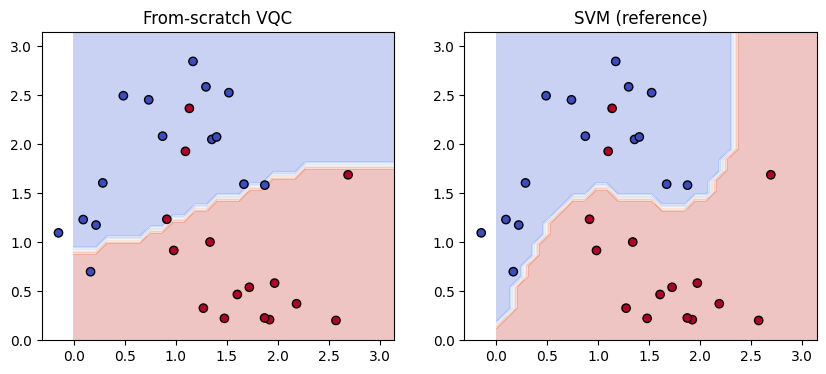

In [ ]:
 svm = SVC(kernel="rbf").fit(X_train_s, y_train)
g = np.linspace(0, np.pi, 30)
xx, yy = np.meshgrid(g, g)
grid = np.c_[xx.ravel(), yy.ravel()]

zones = {"From-scratch VQC": predict_labels(grid, best_theta).reshape(xx.shape),
         "SVM (reference)":  svm.predict(grid).reshape(xx.shape)}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, z) in zip(axes, zones.items()):
    ax.contourf(xx, yy, z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_test_s[:, 0], X_test_s[:, 1], c=y_test, cmap="coolwarm", edgecolor="k")
    ax.set_title(title)
plt.show()